# Airbnb New User Bookings

Задача исследования - изучить данные пользователей Airbnb и определить особенности, влияющие на настройку AutoML для прогноза страны первого бронирования. Целевая переменная `country_destination` задаёт многоклассовую классификацию, включая `NDF` (первое бронирование не совершено).

Данные: [Airbnb New User Bookings (Kaggle)](https://www.kaggle.com/competitions/airbnb-recruiting-new-user-bookings/data).

Для воспроизведения нужны шесть архивов: [train_users_2.csv.zip](https://drive.google.com/file/d/1xYsVZiTMZnLKRbv1aaZwK9TylPEgWDnZ/view?usp=drive_link), [test_users.csv.zip](https://drive.google.com/file/d/1AKL5rIYRdnuuIdqJqmQQZ3wOTU00tKfk/view?usp=drive_link), [sessions.csv.zip](https://drive.google.com/file/d/1ef_PPqTQkv6OpYNr1-UBXXdob3Ri3qTC/view?usp=drive_link), [countries.csv.zip](https://drive.google.com/file/d/1S6e0UXGnBdPmWjkCrzn9RbI7k8zee1BV/view?usp=drive_link), [age_gender_bkts.csv.zip](https://drive.google.com/file/d/1aouzfK10bPMLoY8CEZmkGVFc4iwjdAyA/view?usp=drive_link), [sample_submission_NDF.csv.zip](https://drive.google.com/file/d/1zqA-7FlnTMNogOujjPmVWcFYtdk_964j/view?usp=drive_link). Архивы размещаются рядом с ноутбуком.

## 1. Первичный анализ

Проверяются структура таблиц, типы признаков, целевая переменная и уникальность идентификаторов пользователей.

In [1]:
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

names = ["train_users_2", "test_users", "sessions", "countries",
         "age_gender_bkts", "sample_submission_NDF"]
files = {name: Path(f"{name}.csv.zip") for name in names}
missing_files = [str(path) for path in files.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError("Не найдены архивы: " + ", ".join(missing_files))

train = pd.read_csv(files["train_users_2"], dtype={"id": "string"},
                    parse_dates=["date_account_created", "date_first_booking"], low_memory=False)
test = pd.read_csv(files["test_users"], dtype={"id": "string"},
                   parse_dates=["date_account_created", "date_first_booking"], low_memory=False)
countries = pd.read_csv(files["countries"])
age_gender = pd.read_csv(files["age_gender_bkts"])
submission = pd.read_csv(files["sample_submission_NDF"], dtype={"id": "string"})
session_columns = pd.read_csv(files["sessions"], nrows=0).columns.tolist()

print("Сессии - столбцы:", session_columns)
print("Прочитаны исходные ZIP:", ", ".join(files))

Сессии - столбцы: ['user_id', 'action', 'action_type', 'action_detail', 'device_type', 'secs_elapsed']
Прочитаны исходные ZIP: train_users_2, test_users, sessions, countries, age_gender_bkts, sample_submission_NDF


In [2]:
frames = {"train_users_2": train, "test_users": test,
          "countries": countries, "age_gender_bkts": age_gender,
          "sample_submission_NDF": submission}
structure = pd.DataFrame([
    {"Таблица": name + ".csv", "Строк": len(frame), "Столбцов": frame.shape[1],
     "Полных дублей": int(frame.duplicated().sum()),
     "Столбцов с пропусками": int(frame.isna().any().sum())}
    for name, frame in frames.items()
])
display(structure)
print("sessions.csv: столбцов", len(session_columns), "; число строк рассчитывается в разделе 7")
print("Типы признаков train:")
display(train.dtypes.astype(str).value_counts().to_frame("Столбцов"))
print("Уникальных id в train / test:", train.id.nunique(), test.id.nunique())
print("Пересечение id train и test:", len(set(train.id) & set(test.id)))
print("Цель в train / test:", "country_destination" in train.columns,
      "country_destination" in test.columns)

,Таблица,Строк,Столбцов,Полных дублей,Столбцов с пропусками
0,train_users_2.csv,213451,16,0,3
1,test_users.csv,62096,15,0,3
2,countries.csv,10,7,0,0
3,age_gender_bkts.csv,420,5,0,0
4,sample_submission_NDF.csv,62096,2,0,0


sessions.csv: столбцов 6 ; число строк рассчитывается в разделе 7
Типы признаков train:


,Столбцов
str,10
datetime64[us],2
int64,2
string,1
float64,1


Уникальных id в train / test: 213451 62096
Пересечение id train и test: 0
Цель в train / test: True False


## 2. Распределение целевой переменной

Проверяется число классов, дисбаланс и значение `NDF`. Отсутствие бронирования не следует приравнивать к конкретной стране назначения.

In [3]:
target_counts = train.country_destination.value_counts(dropna=False)
target_table = pd.DataFrame({"Количество": target_counts,
                             "Доля, %": (100 * target_counts / len(train)).round(3)})
display(target_table)
print("Классов:", train.country_destination.nunique(),
      "пропусков цели:", train.country_destination.isna().sum())
print("NDF + US, %:", round(100 * train.country_destination.isin(["NDF", "US"]).mean(), 3))

,Количество,"Доля, %"
country_destination,,
NDF,124543,58.347
US,62376,29.223
other,10094,4.729
FR,5023,2.353
IT,2835,1.328
GB,2324,1.089
ES,2249,1.054
CA,1428,0.669
DE,1061,0.497


Классов: 12 пропусков цели: 0
NDF + US, %: 87.57


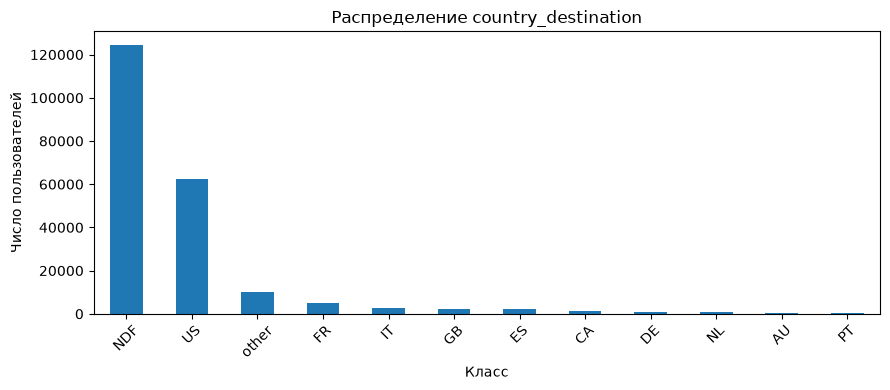

In [4]:
target_counts.plot.bar(figsize=(9, 4))
plt.title("Распределение country_destination")
plt.xlabel("Класс")
plt.ylabel("Число пользователей")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Пропуски и специальные значения

Пропуски сравниваются между train и test по общим столбцам. Отдельно анализируются некорректные значения возраста и обозначение `-unknown-` в категориальных признаках.

In [5]:
common_columns = [c for c in test.columns if c in train.columns]
missing_comparison = pd.DataFrame({
    "train, %": 100 * train[common_columns].isna().mean(),
    "test, %": 100 * test[common_columns].isna().mean()
}).sort_values("train, %", ascending=False)
display(missing_comparison.round(2))
print("Строк с пропуском возраста, train/test:", train.age.isna().sum(), test.age.isna().sum())
print("Строк с возрастом > 100, train/test:", train.age.gt(100).sum(), test.age.gt(100).sum())
print("Строк с возрастом >= 1900, train/test:", train.age.ge(1900).sum(), test.age.ge(1900).sum())
print("Диапазон возраста train:", train.age.min(), train.age.max())

,"train, %","test, %"
date_first_booking,58.35,100.00
age,41.22,46.50
first_affiliate_tracked,2.84,0.03
timestamp_first_active,0.00,0.00
date_account_created,0.00,0.00
gender,0.00,0.00
id,0.00,0.00
signup_method,0.00,0.00
signup_flow,0.00,0.00
affiliate_channel,0.00,0.00


Строк с пропуском возраста, train/test: 87990 28876
Строк с возрастом > 100, train/test: 2345 345
Строк с возрастом >= 1900, train/test: 779 49
Диапазон возраста train: 1.0 2014.0


In [6]:
special_cols = ["gender", "first_browser", "first_device_type", "signup_method"]
special = pd.DataFrame({
    "train: -unknown-": [int(train[c].eq("-unknown-").sum()) for c in special_cols],
    "test: -unknown-": [int(test[c].eq("-unknown-").sum()) for c in special_cols],
}, index=special_cols)
display(special)
print("Пользователей NDF с date_first_booking:",
      int(train.loc[train.country_destination.eq("NDF"), "date_first_booking"].notna().sum()))
print("Остальных пользователей без date_first_booking:",
      int(train.loc[train.country_destination.ne("NDF"), "date_first_booking"].isna().sum()))
print("Заполнено date_first_booking в test:", int(test.date_first_booking.notna().sum()))

,train: -unknown-,test: -unknown-
gender,95688,33792
first_browser,27266,17128
first_device_type,0,0
signup_method,0,0


Пользователей NDF с date_first_booking: 0
Остальных пользователей без date_first_booking: 0
Заполнено date_first_booking в test: 0


Возраст 18-100 в train: 122958 ; в test: 32845


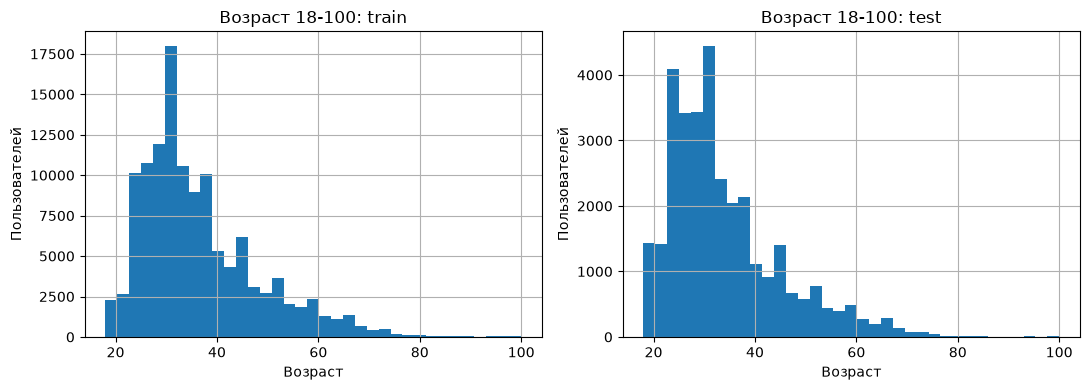

In [7]:
valid_age_train = train.age.between(18, 100)
valid_age_test = test.age.between(18, 100)
print("Возраст 18-100 в train:", int(valid_age_train.sum()),
      "; в test:", int(valid_age_test.sum()))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train.loc[valid_age_train, "age"].hist(ax=axes[0], bins=35)
test.loc[valid_age_test, "age"].hist(ax=axes[1], bins=35)
axes[0].set_title("Возраст 18-100: train")
axes[1].set_title("Возраст 18-100: test")
for ax in axes:
    ax.set_xlabel("Возраст")
    ax.set_ylabel("Пользователей")
plt.tight_layout()
plt.show()

## 4. Категориальные признаки и связь с целью

Анализируются разнообразие категорий и неоднородность доли `NDF`. Наблюдаемые различия не означают причинного влияния признаков.

In [8]:
category_columns = ["gender", "signup_method", "language", "affiliate_channel",
                    "affiliate_provider", "first_affiliate_tracked", "signup_app",
                    "first_device_type", "first_browser"]
cardinality = pd.DataFrame({
    "train": [train[col].nunique(dropna=True) for col in category_columns],
    "test": [test[col].nunique(dropna=True) for col in category_columns]
}, index=category_columns)
display(cardinality.sort_values("train", ascending=False))
for col in ["signup_app", "first_device_type", "gender"]:
    print("Частые значения:", col)
    display(train[col].value_counts(dropna=False).head(8).to_frame("Пользователей"))

,train,test
first_browser,52,31
language,25,24
affiliate_provider,18,17
first_device_type,9,9
affiliate_channel,8,7
first_affiliate_tracked,7,7
gender,4,4
signup_app,4,4
signup_method,3,4


Частые значения: signup_app


,Пользователей
signup_app,
Web,182717
iOS,19019
Moweb,6261
Android,5454


Частые значения: first_device_type


,Пользователей
first_device_type,
Mac Desktop,89600
Windows Desktop,72716
iPhone,20759
iPad,14339
Other/Unknown,10667
Android Phone,2803
Android Tablet,1292
Desktop (Other),1199


Частые значения: gender


,Пользователей
gender,
-unknown-,95688
FEMALE,63041
MALE,54440
OTHER,282


In [9]:
for col in ["signup_app", "first_device_type", "gender"]:
    by_group = (train.groupby(col, dropna=False)
                .agg(Пользователей=("id", "size"),
                     Доля_NDF=("country_destination", lambda s: 100 * s.eq("NDF").mean()))
                .sort_values("Пользователей", ascending=False))
    print("Доля NDF по признаку", col)
    display(by_group.head(10).round(2))

Доля NDF по признаку signup_app


,Пользователей,Доля_NDF
signup_app,,
Web,182717,56.20
iOS,19019,71.02
Moweb,6261,65.77
Android,5454,77.39


Доля NDF по признаку first_device_type


,Пользователей,Доля_NDF
first_device_type,,
Mac Desktop,89600,52.85
Windows Desktop,72716,58.53
iPhone,20759,69.09
iPad,14339,61.89
Other/Unknown,10667,73.05
Android Phone,2803,74.49
Android Tablet,1292,64.40
Desktop (Other),1199,54.13
SmartPhone (Other),76,67.11


Доля NDF по признаку gender


,Пользователей,Доля_NDF
gender,,
-unknown-,95688,69.67
FEMALE,63041,49.25
MALE,54440,49.08
OTHER,282,37.59


## 5. Временная структура и согласованность дат

Проверяются хронология регистрации, первая активность и первая бронь. Для прогноза будущих пользователей требуется учитывать последовательность появления аккаунтов.

In [10]:
for name, frame in [("train", train), ("test", test)]:
    active_at = pd.to_datetime(frame.timestamp_first_active.astype("string"),
                               format="%Y%m%d%H%M%S", errors="coerce")
    print(name, "создание аккаунта:", frame.date_account_created.min(), "—",
          frame.date_account_created.max())
    print(name, "первая активность:", active_at.min(), "—", active_at.max(),
          "; некорректных/пустых:", int(active_at.isna().sum()))
    print(name, "первая активность раньше регистрации:",
          int((active_at.dt.normalize() < frame.date_account_created).sum()))
print("Бронь до даты регистрации:",
      int((train.date_first_booking < train.date_account_created).sum()))
print("Первая бронь: диапазон", train.date_first_booking.min(), "—",
      train.date_first_booking.max())

train создание аккаунта: 2010-01-01 00:00:00 — 2014-06-30 00:00:00
train первая активность: 2009-03-19 04:32:55 — 2014-06-30 23:58:24 ; некорректных/пустых: 0
train первая активность раньше регистрации: 178
test создание аккаунта: 2014-07-01 00:00:00 — 2014-09-30 00:00:00
test первая активность: 2014-07-01 00:00:06 — 2014-09-30 23:59:01 ; некорректных/пустых: 0
test первая активность раньше регистрации: 0
Бронь до даты регистрации: 29
Первая бронь: диапазон 2010-01-02 00:00:00 — 2015-06-29 00:00:00


,train,test
date_account_created,,
2013-06,6765,0
2013-07,7950,0
2013-08,8369,0
2013-09,9125,0
2013-10,7862,0
2013-11,7751,0
2013-12,8361,0
2014-01,11111,0
2014-02,9967,0


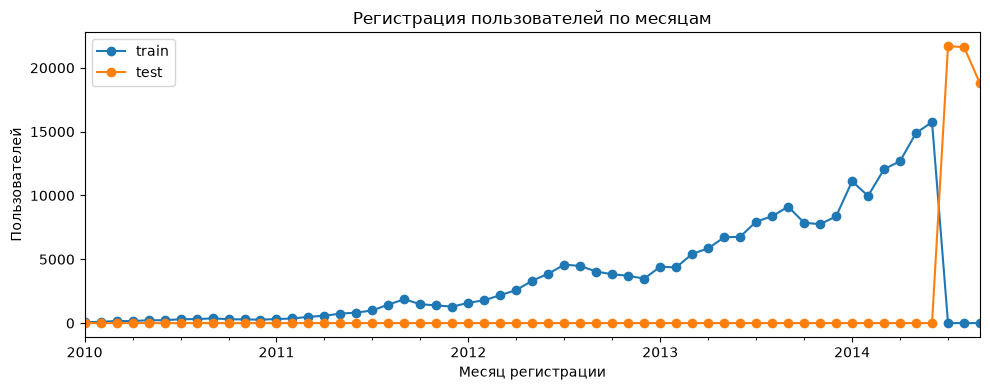

In [11]:
cohorts = pd.DataFrame({
    "train": train.groupby(train.date_account_created.dt.to_period("M")).size(),
    "test": test.groupby(test.date_account_created.dt.to_period("M")).size()
}).fillna(0).astype(int)
display(cohorts.tail(16))
cohorts.plot(figsize=(10, 4), marker="o")
plt.title("Регистрация пользователей по месяцам")
plt.xlabel("Месяц регистрации")
plt.ylabel("Пользователей")
plt.tight_layout()
plt.show()

## 6. Сравнение train/test

Проверяются различия в источниках регистрации, типах устройств и распределении пропусков. Отсутствие общих `id` не исключает сдвиг распределения признаков.

In [12]:
shift_rows = []
for col in ["signup_app", "first_device_type", "gender", "first_browser", "signup_method"]:
    train_share = train[col].value_counts(normalize=True, dropna=False)
    test_share = test[col].value_counts(normalize=True, dropna=False)
    for value in set(train_share.index.tolist()) | set(test_share.index.tolist()):
        a = 100 * train_share.get(value, 0)
        b = 100 * test_share.get(value, 0)
        shift_rows.append({"Признак": col, "Значение": str(value), "train, %": a,
                           "test, %": b, "Изменение, п.п.": b - a})
shift = pd.DataFrame(shift_rows)
display(shift.reindex(shift["Изменение, п.п."].abs().sort_values(ascending=False).index)
        .head(15).round(2))

,Признак,Значение,"train, %","test, %","Изменение, п.п."
0,signup_app,Web,85.60,59.91,-25.69
5,first_device_type,iPhone,9.73,30.69,20.96
1,signup_app,iOS,8.91,25.08,16.17
6,first_device_type,Mac Desktop,41.98,26.94,-15.04
43,first_browser,-unknown-,12.77,27.58,14.81
8,first_device_type,Windows Desktop,34.07,22.92,-11.15
16,gender,-unknown-,44.83,54.42,9.59
11,first_device_type,Android Phone,1.31,10.72,9.40
38,first_browser,Safari,21.16,13.10,-8.06
56,first_browser,Firefox,15.77,8.07,-7.70


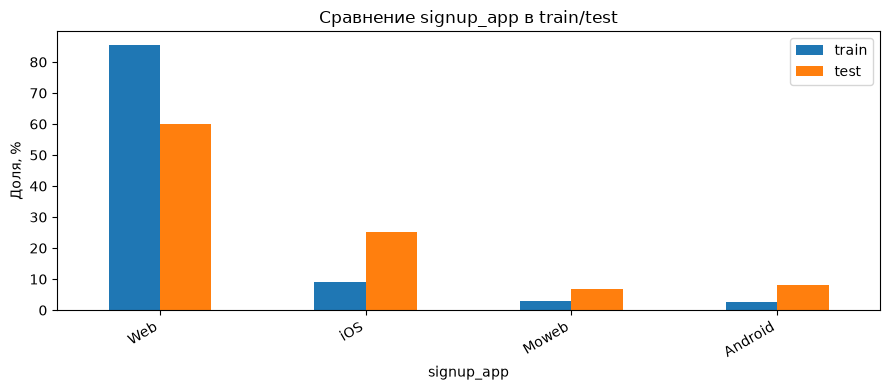

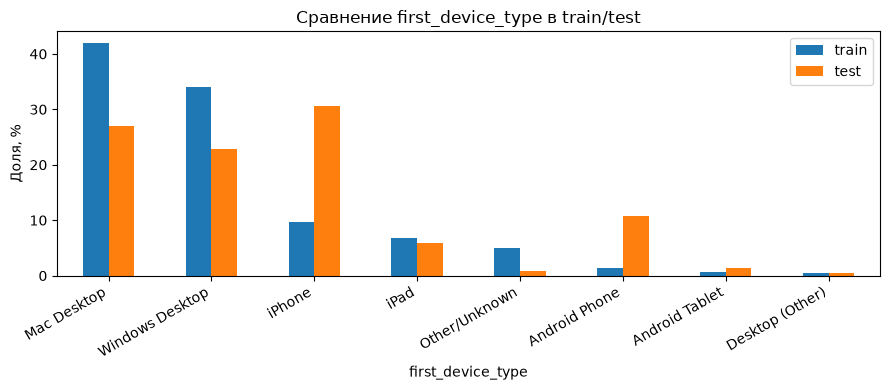

In [13]:
for col in ["signup_app", "first_device_type"]:
    comp = pd.DataFrame({"train": 100 * train[col].value_counts(normalize=True),
                         "test": 100 * test[col].value_counts(normalize=True)}).fillna(0)
    comp.sort_values("train", ascending=False).head(8).plot.bar(figsize=(9, 4))
    plt.title("Сравнение " + col + " в train/test")
    plt.ylabel("Доля, %")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 7. Журнал пользовательских сессий

`sessions.csv` содержит события нескольких действий одного пользователя. Журнал читается частями; проверяются ключи, пропуски, покрытие обучающих и тестовых пользователей, а также ограничения времени событий.

In [14]:
train_ids = set(train.id.dropna())
test_ids = set(test.id.dropna())
per_user_events = Counter()
action_counts = Counter()
action_type_counts = Counter()
action_detail_values = set()
device_counts = Counter()
booking_request_users = set()
session_missing = Counter()
rows_sessions = rows_train = rows_test = rows_other = 0
long_elapsed = negative_elapsed = missing_ids = 0
max_elapsed = None

for chunk in pd.read_csv(files["sessions"], chunksize=150_000,
                         dtype={"user_id": "string", "action": "string",
                                "action_type": "string", "action_detail": "string",
                                "device_type": "string"}):
    rows_sessions += len(chunk)
    session_missing.update(chunk.isna().sum().to_dict())
    ids = chunk.user_id.dropna()
    missing_ids += int(chunk.user_id.isna().sum())
    per_user_events.update(ids.value_counts().to_dict())
    action_counts.update(chunk.action.dropna().value_counts().to_dict())
    action_type_counts.update(chunk.action_type.dropna().value_counts().to_dict())
    device_counts.update(chunk.device_type.dropna().value_counts().to_dict())
    action_detail_values.update(chunk.action_detail.dropna().unique().tolist())
    rows_train += int(chunk.user_id.isin(train_ids).sum())
    rows_test += int(chunk.user_id.isin(test_ids).sum())
    elapsed = pd.to_numeric(chunk.secs_elapsed, errors="coerce")
    long_elapsed += int(elapsed.gt(86_400).sum())
    negative_elapsed += int(elapsed.lt(0).sum())
    if elapsed.notna().any():
        maximum = elapsed.max()
        max_elapsed = maximum if max_elapsed is None else max(max_elapsed, maximum)
    booking_request_users.update(chunk.loc[chunk.action_type.eq("booking_request").fillna(False),
                                          "user_id"].dropna().unique().tolist())
rows_other = rows_sessions - rows_train - rows_test - missing_ids
print("Строк в sessions:", rows_sessions)
print("Пользователей с событиями:", len(per_user_events))
print("Событий: train/test/вне обеих таблиц/без id:",
      rows_train, rows_test, rows_other, missing_ids)

Строк в sessions: 10567737
Пользователей с событиями: 135483
Событий: train/test/вне обеих таблиц/без id: 5537957 4995284 0 34496


In [15]:
train_session_users = train_ids & per_user_events.keys()
test_session_users = test_ids & per_user_events.keys()
coverage = pd.DataFrame([
    {"Выборка": "train", "Пользователей": len(train_ids),
     "Есть события": len(train_session_users),
     "Покрытие, %": 100 * len(train_session_users) / len(train_ids)},
    {"Выборка": "test", "Пользователей": len(test_ids),
     "Есть события": len(test_session_users),
     "Покрытие, %": 100 * len(test_session_users) / len(test_ids)}
])
display(coverage.round(2))
display(pd.Series(session_missing).sort_values(ascending=False).to_frame("Пропусков"))
print("Уникальных action / action_type / action_detail:",
      len(action_counts), len(action_type_counts), len(action_detail_values))
print("secs_elapsed > 86400:", long_elapsed, "отрицательных:", negative_elapsed,
      "максимум:", max_elapsed)
events_per_user = pd.Series(per_user_events, dtype="int64")
print("Событий на пользователя, медиана / P99 / максимум:",
      events_per_user.median(), events_per_user.quantile(.99), events_per_user.max())
print("Самые частые действия:")
display(pd.Series(action_counts).sort_values(ascending=False).head(12).to_frame("Событий"))
print("Типы действий:")
display(pd.Series(action_type_counts).sort_values(ascending=False).to_frame("Событий"))

,Выборка,Пользователей,Есть события,"Покрытие, %"
0,train,213451,73815,34.58
1,test,62096,61668,99.31


,Пропусков
action_detail,1126204
action_type,1126204
secs_elapsed,136031
action,79626
user_id,34496
device_type,0


Уникальных action / action_type / action_detail: 359 10 155
secs_elapsed > 86400: 435170 отрицательных: 0 максимум: 1799977.0
Событий на пользователя, медиана / P99 / максимум: 41.0 538.0 2722
Самые частые действия:


,Событий
show,2768278
index,843699
search_results,725226
personalize,706824
search,536057
ajax_refresh_subtotal,487744
update,365130
similar_listings,364624
social_connections,339000
reviews,320591


Типы действий:


,Событий
view,3560902
data,2103770
click,1996183
-unknown-,1031170
submit,623357
message_post,87103
partner_callback,19132
booking_request,18773
modify,1139
booking_response,4


In [16]:
has_session = train.id.isin(train_session_users)
coverage_by_target = (train.assign(has_session=has_session)
                      .groupby("country_destination")
                      .agg(Пользователей=("id", "size"),
                           С_сессиями=("has_session", "sum")))
coverage_by_target["Доля, %"] = 100 * coverage_by_target.С_сессиями / coverage_by_target.Пользователей
display(coverage_by_target.sort_values("Пользователей", ascending=False).round(2))
booking_train = train.loc[train.id.isin(booking_request_users)]
print("Пользователей с booking_request, всего:", len(booking_request_users))
print("Среди train:", len(booking_train),
      "; NDF:", int(booking_train.country_destination.eq("NDF").sum()),
      "; остальные:", int(booking_train.country_destination.ne("NDF").sum()))
print("Абсолютных временных меток событий в sessions.csv нет:",
      not any("timestamp" in c or "date" in c for c in session_columns))

,Пользователей,С_сессиями,"Доля, %"
country_destination,,,
NDF,124543,45041,36.17
US,62376,20095,32.22
other,10094,3655,36.21
FR,5023,1435,28.57
IT,2835,979,34.53
GB,2324,731,31.45
ES,2249,707,31.44
CA,1428,440,30.81
DE,1061,250,23.56


Пользователей с booking_request, всего: 17495
Среди train: 10003 ; NDF: 1537 ; остальные: 8466
Абсолютных временных меток событий в sessions.csv нет: True


## 8. Дополнительные таблицы и связи

Справочники `countries` и `age_gender_bkts` содержат агрегаты по странам назначения, а не по пользователям. `sample_submission_NDF` задаёт формат ответа. Проверяется, какие таблицы можно безопасно связать с пользователями при неизвестной цели.

In [17]:
print("countries: уникальных country_destination:",
      countries.country_destination.nunique(),
      "; повторных:", int(countries.country_destination.duplicated().sum()))
print("age_gender_bkts: строк / уникальных сочетаний страна-возраст-пол:",
      len(age_gender),
      age_gender[["country_destination", "age_bucket", "gender"]].drop_duplicates().shape[0])
print("Страны, представленные в train, но отсутствующие в countries:",
      sorted(set(train.country_destination.dropna()) - set(countries.country_destination.dropna())))
print("Страны справочника age_gender_bkts:", age_gender.country_destination.nunique())
print("Пример справочников:")
display(countries.head(5))
display(age_gender.head(5))

countries: уникальных country_destination: 10 ; повторных: 0
age_gender_bkts: строк / уникальных сочетаний страна-возраст-пол: 420 420
Страны, представленные в train, но отсутствующие в countries: ['NDF', 'other']
Страны справочника age_gender_bkts: 10
Пример справочников:


,country_destination,lat_destination,lng_destination,distance_km,destination_km2,destination_language,language_levenshtein_distance
0,AU,-26.853388,133.275160,15297.7440,7741220.0,eng,0.00
1,CA,62.393303,-96.818146,2828.1333,9984670.0,eng,0.00
2,DE,51.165707,10.452764,7879.5680,357022.0,deu,72.61
3,ES,39.896027,-2.487694,7730.7240,505370.0,spa,92.25
4,FR,46.232193,2.209667,7682.9450,643801.0,fra,92.06


,age_bucket,country_destination,gender,population_in_thousands,year
0,100+,AU,male,1.0,2015.0
1,95-99,AU,male,9.0,2015.0
2,90-94,AU,male,47.0,2015.0
3,85-89,AU,male,118.0,2015.0
4,80-84,AU,male,199.0,2015.0


In [19]:
print("submission: строк / уникальных id:", len(submission), submission.id.nunique())
print("id submission вне test:", len(set(submission.id) - test_ids))
print("id test вне submission:", len(test_ids - set(submission.id)))
print("Метка country в submission, уникальных:", submission.country.nunique())

submission: строк / уникальных id: 62096 62096
id submission вне test: 0
id test вне submission: 0
Метка country в submission, уникальных: 1


## 9. Проверка предпосылок валидации и утечек

В исходном train/test используется хронологическое разделение по дате регистрации. Для внутренней оценки рассматривается более поздняя когорта обучающих пользователей. `date_first_booking` непосредственно раскрывает наличие бронирования, а в `sessions` отсутствует абсолютное время события.

In [20]:
ordered = train.sort_values(["date_account_created", "id"])
cutoff = ordered.date_account_created.iloc[int(.8 * len(ordered))]
before = train.loc[train.date_account_created < cutoff]
after = train.loc[train.date_account_created >= cutoff]
validation_summary = pd.DataFrame([
    {"Часть": "Train", "Пользователей": len(before),
     "NDF, %": 100 * before.country_destination.eq("NDF").mean(),
     "Классов": before.country_destination.nunique()},
    {"Часть": "Validation", "Пользователей": len(after),
     "NDF, %": 100 * after.country_destination.eq("NDF").mean(),
     "Классов": after.country_destination.nunique()}
])
print("Граница внутренней хронологической валидации:", cutoff)
display(validation_summary.round(2))
print("Пересечение пользователей Train/Validation:", len(set(before.id) & set(after.id)))
print("Классы, отсутствующие в обучающей части:",
      sorted(set(after.country_destination) - set(before.country_destination)))
print("Дата первого бронирования заполнена только у пользователей не-NDF:",
      bool(train.date_first_booking.notna().equals(train.country_destination.ne("NDF"))))

Граница внутренней хронологической валидации: 2014-04-02 00:00:00


,Часть,Пользователей,"NDF, %",Классов
0,Train,170523,57.5,12
1,Validation,42928,61.7,12


Пересечение пользователей Train/Validation: 0
Классы, отсутствующие в обучающей части: []
Дата первого бронирования заполнена только у пользователей не-NDF: True


## 10. Выводы для настройки AutoML

1. Целевая переменная `country_destination` задаёт многоклассовую классификацию с 12 классами; `NDF` обозначает отсутствие первого бронирования, а не страну. Дисбаланс классов требует выбора метрики с учётом бизнес-задачи.
2. Основная обучающая таблица - `train_users_2.csv`, прогноз строится для `test_users.csv`. `date_first_booking` и любые признаки наличия этой даты исключаются, поскольку раскрывают целевой исход.
3. Возраст содержит пропуски и неправдоподобные значения, а категориальные признаки - специальные обозначения `-unknown-`. Требуется различать кодированные и фактические пропуски.
4. Для прогноза новых пользователей предпочтительна хронологическая валидация. Внутренний holdout не гарантирует, что для всех пользователей класса `NDF` исход был окончательно установлен к границе обучения: горизонт наблюдения нужно уточнять.
5. Журнал `sessions.csv` имеет покрытие train/test с большим различием и не содержит абсолютных временных меток событий. Поэтому включать агрегаты по сессиям в базовую модель без подтверждения их доступности до прогноза нельзя.
6. `countries.csv` и `age_gender_bkts.csv` описывают страны назначения, а не пользователей. Присоединять их к наблюдениям по фактической `country_destination` нельзя: у test цель неизвестна.
7. `sample_submission_NDF.csv` используется для проверки формата и соответствия идентификаторов, но не как источник признаков или меток.
8. Между train/test наблюдается изменение распределений категорий и периода регистрации; его необходимо учитывать при интерпретации качества модели.